In [83]:
# INF201 - Deliverable 1
# Task 1: Temperature 


%pip install requests
%pip install pandas
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [85]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

"""This is how i retrieved data from frost.met.no"""

with open('secrets.txt', 'r') as f:
    client_id = f.read().strip() 
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, parameters, auth=(client_id,''))
json = r.json()

if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

Data retrieved from frost.met.no!


How to see where dates and temperatures are hiding

In [3]:
print(data[0])

{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'mean(air_temperature P1D)', 'value': -5.2, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}, {'elementId': 'mean(air_temperature P1D)', 'value': -2.8, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT6H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1'}]}


Extracting the data using pandas

In [45]:
rows = [] #empty list
for item in data:
    row = {  #dict
        "time": item["referenceTime"], #Here i am just saying that i named "time" out of "referenceTime", because that is where the "date" is located
        "temperature": item["observations"][0]["value"], #Same logic for temperature, but that is in "observations", and must be the first [0] which representes 'elementId': 'mean(air_temperature P1D)', and [value] gives me the value for the temperature, which comes right after [0]
    }
    rows.append(row) #i just append the dict i made in the list "rows"

df = pd.DataFrame(rows) #here header shows the first 5 rows
df["time"]= pd.to_datetime(df["time"]) #This converts the arguments in time into actual dates
print(df.head()) 

                       time  temperature
0 2025-01-01 00:00:00+00:00         -5.2
1 2025-01-02 00:00:00+00:00        -11.5
2 2025-01-03 00:00:00+00:00         -8.9
3 2025-01-04 00:00:00+00:00        -15.5
4 2025-01-05 00:00:00+00:00        -12.5


Plotting


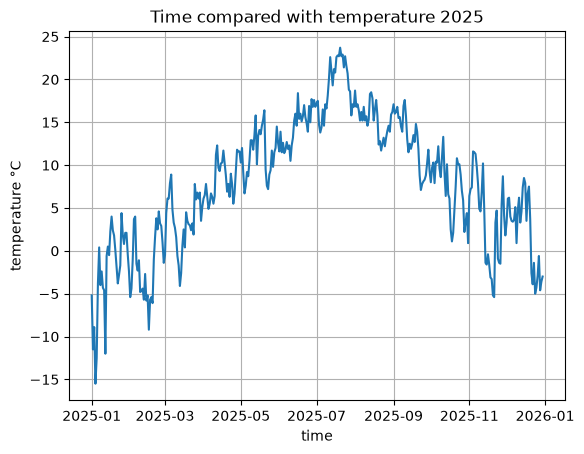

In [46]:
plt.plot(df["time"], df["temperature"]) #Sets time on x position, and temperature on the y position
plt.xlabel("time") #name for the x-axis
plt.ylabel("temperature °C") #name for the y-axis
plt.title("Time compared with temperature 2025") #title
plt.grid(True) #makes grid lines on the background, looks nice

Summary table for temperature values in 2025

In [80]:
summary_table = df["temperature"]
all_values = summary_table.describe() #decribe gives us all the values and more, and median is actually called 50% here, because median is the middle value of the whole datasett
specific_values = all_values.loc[["mean","50%", "min","max"]] #Getting the specfic values from .describe()
renamed_to_median = specific_values.rename({"50%" : "median"}) #renaming 50% to median
summary_table_fixed = renamed_to_median #Now i created a variable that has the specific_values AND the rename of 50% to median
converting_to_dataframe = summary_table_fixed.to_frame(name="Temperature °C") #This converts Series to a Dataframe, so it removes the footer
print(converting_to_dataframe.round(2))

        Temperature °C
mean               7.9
median             8.4
min              -15.5
max               23.7
